# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
# Định nghĩa đầy đủ các thành phần của bài toán tìm kiếm đối kháng trong Mean Connect 4:
# 1. Initial state (Trạng thái khởi đầu): Bàn cờ rỗng kích thước (R, C), tất cả các ô có giá trị 0.
# 2. Actions(s, player): Tập hành động hợp lệ cho người chơi 'player' (+1 hoặc -1):
#    - Nước đi thả quân thông thường: Thả vào cột c còn chỗ trống (state[0, c] == 0).
#    - Nước đi 'Mean' (chơi xấu): Lấy quân của đối thủ ở hàng đáy (row R-1, state[R-1, c_rem] == -player),
#      toàn bộ các quân phía trên rơi xuống 1 ô, và thả lại quân đó vào cột c_drop bất kỳ còn chỗ.
# 3. Transition model Result(s, player, a): Trả về bàn cờ mới s' sau khi thực hiện hành động a.
# 4. Terminal test Terminal(s): Trạng thái kết thúc khi có 4 quân thẳng hàng (ngang, dọc, chéo) hoặc bàn cờ đầy.
# 5. Utility(s, player): +1 nếu 'player' thắng, -1 nếu thua, 0 nếu hòa, None nếu chưa kết thúc.

import numpy as np
import mean_connect4 as mc
b0 = mc.empty_board((6, 7))
print('Trạng thái khởi đầu (6x7):\n', b0)
print('Số hành động khởi đầu hợp lệ cho người chơi 1:', len(mc.actions(b0, player=1)))

Trạng thái khởi đầu (6x7):
 [[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
Số hành động khởi đầu hợp lệ cho người chơi 1: 7


How big is the state space? Give an estimate and explain it.

In [2]:
# Tính toán kích thước không gian trạng thái của Mean Connect 4 trên bàn cờ chuẩn 6x7:
# Mỗi ô có 3 khả năng: Trống (0), Quân Đỏ (+1), Quân Vàng (-1).
# Giới hạn trên thô: 3^(6 * 7) = 3^42 ≈ 1.094 × 10^20 trạng thái.
# Tuy nhiên, do luật trọng lực (quân rơi xuống đáy), mỗi cột có số lượng cấu hình hợp lệ là:
# sum_{k=0}^{R} 2^k = 2^(R+1) - 1. Với R=6: 2^7 - 1 = 127 cấu hình/cột.
# Không gian trạng thái tuân thủ trọng lực: 127^7 ≈ 5.26 × 10^14 trạng thái.
# (Trong Mean Connect 4, trọng lực vẫn được duy trì sau khi rút quân đáy vì các quân trên rơi xuống).

R, C = 6, 7
upper_bound = 3 ** (R * C)
col_states = (2 ** (R + 1)) - 1
gravity_states = col_states ** C

print(f'Giới hạn trên lý thuyết (3^42): {upper_bound:.4e}')
print(f'Số cấu hình mỗi cột tuân thủ trọng lực: {col_states}')
print(f'Không gian trạng thái hợp lệ ước tính (127^7): {gravity_states:.4e}')

Giới hạn trên lý thuyết (3^42): 1.0942e+20
Số cấu hình mỗi cột tuân thủ trọng lực: 127
Không gian trạng thái hợp lệ ước tính (127^7): 5.3288e+14


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [3]:
# Kích thước cây trò chơi (Game Tree Size) trong Mean Connect 4:
# Trong Connect 4 thông thường, hệ số nhánh b ≤ 7. Số nước đi trung bình d ≈ 36. Cây trò chơi ≈ 7^36 ≈ 2.6 × 10^30.
# Trong Mean Connect 4, người chơi có thêm các nước 'Mean':
# - Thả quân thông thường: Tối đa C lựa chọn (cột 0 đến C-1).
# - Nước 'Mean': Chọn cột rút quân đáy của đối thủ (tối đa C) × Chọn cột thả lại (tối đa C) = C^2 lựa chọn.
# Tổng hệ số nhánh tối đa b_max = C + C^2 = 7 + 49 = 56 nhánh mỗi lượt!
# Vì vậy, cây trò chơi bùng nổ tổ hợp dữ dội hơn Connect 4 chuẩn rất nhiều: b^d ≈ 20^36 ≈ 10^46.

b_std = 7
b_mean_max = 7 + 7*7
d_avg = 36
print(f'Hệ số nhánh tối đa của Connect 4 chuẩn: {b_std}')
print(f'Hệ số nhánh tối đa của Mean Connect 4: {b_mean_max}')
print(f'Kích thước cây trò chơi ước lượng (b_mean_avg ≈ 15, d ≈ 36): {15**36:.4e}')

Hệ số nhánh tối đa của Connect 4 chuẩn: 7
Hệ số nhánh tối đa của Mean Connect 4: 56
Kích thước cây trò chơi ước lượng (b_mean_avg ≈ 15, d ≈ 36): 2.1842e+42


## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [4]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

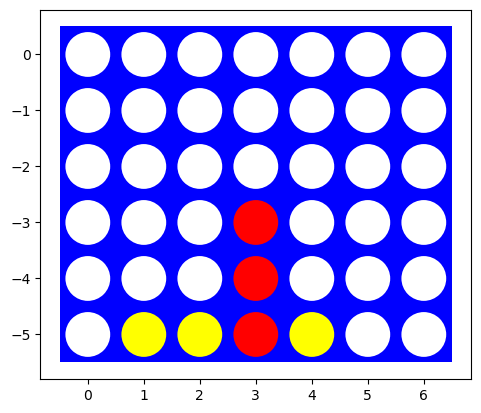

In [5]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [6]:
import numpy as np
import mean_connect4 as mc

# Tái sử dụng các hàm tối ưu từ module mean_connect4:
actions = mc.actions
result = mc.result
check_win = mc.check_win
utility = mc.utility
terminal = mc.terminal

# Kiểm tra tính đúng đắn trên một bàn cờ mẫu
demo_board = mc.empty_board((4, 4))
demo_board = result(demo_board, 1, ('drop', 0))
demo_board = result(demo_board, -1, ('drop', 1))
print('Bàn cờ 4x4 sau 2 nước:')
print(demo_board)
print('\nDanh sách nước đi hợp lệ cho Player 1:')
print(actions(demo_board, player=1))
print('Kiểm tra Terminal:', terminal(demo_board))
print('Utility cho Player 1:', utility(demo_board, player=1))

Bàn cờ 4x4 sau 2 nước:
[[ 0  0  0  0]
 [ 0  0  0  0]
 [ 0  0  0  0]
 [ 1 -1  0  0]]

Danh sách nước đi hợp lệ cho Player 1:
[('drop', 0), ('drop', 1), ('drop', 2), ('drop', 3), ('mean', 1, 0), ('mean', 1, 1), ('mean', 1, 2), ('mean', 1, 3)]
Kiểm tra Terminal: False
Utility cho Player 1: None


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [7]:
import random
from mean_connect4 import random_player

# Kiểm thử tác tử ngẫu nhiên chọn nước đi
test_b = mc.empty_board((6, 7))
act_rnd = random_player(test_b, player=1)
print('Nước đi ngẫu nhiên được chọn trên bàn cờ rỗng:', act_rnd)

Nước đi ngẫu nhiên được chọn trên bàn cờ rỗng: ('drop', 1)


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [8]:
import time
from mean_connect4 import play, random_player

print('Tiến hành mô phỏng 1.000 ván đấu giữa Random vs Random trên bàn cờ nhỏ (4x4) để thu thập thống kê...')
t0 = time.perf_counter()
res_1000 = play(random_player, random_player, N=1000, shape=(4, 4), win_length=3, seed=42)
elapsed = time.perf_counter() - t0

print(f'Kết quả 1.000 ván Random vs Random: {res_1000}')
print(f'Tỷ lệ Thắng Người 1 (Red - đi trước): {res_1000["1"] / 10:.1f}%')
print(f'Tỷ lệ Thắng Người 2 (Yellow - đi sau): {res_1000["-1"] / 10:.1f}%')
print(f'Tỷ lệ Hòa: {res_1000["draw"] / 10:.1f}%')
print(f'Thời gian chạy: {elapsed:.2f} giây')

print('\nNhận xét:')
print('- Người chơi đi trước (Player 1) có ưu thế áp đảo do được đi trước và tạo thế cờ chủ động.')

Tiến hành mô phỏng 1.000 ván đấu giữa Random vs Random trên bàn cờ nhỏ (4x4) để thu thập thống kê...


Kết quả 1.000 ván Random vs Random: {'1': 802, '-1': 198, 'draw': 0}
Tỷ lệ Thắng Người 1 (Red - đi trước): 80.2%
Tỷ lệ Thắng Người 2 (Yellow - đi sau): 19.8%
Tỷ lệ Hòa: 0.0%
Thời gian chạy: 0.37 giây

Nhận xét:
- Người chơi đi trước (Player 1) có ưu thế áp đảo do được đi trước và tạo thế cờ chủ động.


## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [9]:
from mean_connect4 import minimax_alpha_beta, minimax_player_factory

# Khởi tạo tác tử Minimax với cắt tỉa Alpha-Beta
minimax_player = minimax_player_factory(depth=None, win_length=3)
print('Minimax Search với cắt tỉa Alpha-Beta đã sẵn sàng.')

Minimax Search với cắt tỉa Alpha-Beta đã sẵn sàng.


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [10]:
# Tạo 5 thế cờ kiểm thử để đánh giá độ nhạy bén chiến thuật của tác tử:
# Case 1: Thắng ngay bằng nước thả thông thường
# Case 2: Chặn đối thủ thắng ngay
# Case 3: Cơ hội dùng nước 'Mean' để phá thế cờ của đối thủ
# Case 4: Thế cờ phức tạp ở giữa ván
# Case 5: Bẫy chiến thuật 2 mang

test_cases = []

# Board 1: Player 1 có hàng ngang 2 quân liên tiếp, cần thả ô cột 2 để đủ 3 quân thắng
b1 = mc.empty_board((4, 4))
b1[3, 0] = 1; b1[3, 1] = 1; b1[3, 3] = -1
test_cases.append(('Thắng ngay nước thường', b1, 1))

# Board 2: Đối thủ (-1) có 2 quân liên tiếp, Player 1 phải chặn
b2 = mc.empty_board((4, 4))
b2[3, 0] = -1; b2[3, 1] = -1; b2[2, 0] = 1
test_cases.append(('Chặn đối thủ thắng', b2, 1))

# Board 3: Đối thủ có quân ở đáy cột 0, Player 1 dùng nước Mean để rút đáy
b3 = mc.empty_board((4, 4))
b3[3, 0] = -1; b3[2, 0] = 1; b3[3, 1] = 1
test_cases.append(('Thế cờ có lựa chọn Mean', b3, 1))

# Board 4: Thế cờ phân tán cột giữa
b4 = mc.empty_board((4, 4))
b4[3, 1] = 1; b4[3, 2] = -1; b4[2, 1] = -1
test_cases.append(('Thế cờ tranh chấp trung tâm', b4, 1))

# Board 5: Bàn cờ rỗng
b5 = mc.empty_board((4, 4))
test_cases.append(('Bàn cờ rỗng 4x4', b5, 1))

print('=== KIỂM THỬ TÁC TỬ MINIMAX TRÊN 5 THẾ CỜ ===')
for name, board, player in test_cases:
    t0 = time.perf_counter()
    val, act = minimax_alpha_beta(board, player=player, depth=4, win_length=3)
    t_ms = (time.perf_counter() - t0) * 1000
    print(f'{name:<30} -> Nước chọn: {str(act):<18} | Giá trị: {val:+.2f} | Thời gian: {t_ms:.2f}ms')

=== KIỂM THỬ TÁC TỬ MINIMAX TRÊN 5 THẾ CỜ ===
Thắng ngay nước thường         -> Nước chọn: ('drop', 2)        | Giá trị: +1.00 | Thời gian: 18.94ms
Chặn đối thủ thắng             -> Nước chọn: ('mean', 1, 0)     | Giá trị: -0.00 | Thời gian: 47.10ms
Thế cờ có lựa chọn Mean        -> Nước chọn: ('drop', 2)        | Giá trị: +1.00 | Thời gian: 62.71ms


Thế cờ tranh chấp trung tâm    -> Nước chọn: ('drop', 1)        | Giá trị: -0.00 | Thời gian: 85.13ms


Bàn cờ rỗng 4x4                -> Nước chọn: ('drop', 2)        | Giá trị: -0.00 | Thời gian: 39.78ms


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [11]:
# Đo thời gian ra quyết định khi tăng dần kích thước bàn cờ
boards_to_test = [(3, 3), (3, 4), (4, 4)]
print('=== THỜI GIAN DUYỆT CỦA MINIMAX KHI TĂNG KÍCH THƯỚC BÀN CỜ ===')
for shape in boards_to_test:
    b = mc.empty_board(shape)
    mc.node_counter = 0
    t0 = time.perf_counter()
    val, act = minimax_alpha_beta(b, player=1, depth=None if shape != (4,4) else 6, win_length=3)
    t_s = time.perf_counter() - t0
    print(f'Kích thước {shape[0]}x{shape[1]} -> Nước đi: {str(act):<15} | Số nút: {mc.node_counter:<8} | Thời gian: {t_s:.4f}s')

=== THỜI GIAN DUYỆT CỦA MINIMAX KHI TĂNG KÍCH THƯỚC BÀN CỜ ===
Kích thước 3x3 -> Nước đi: ('drop', 1)     | Số nút: 9450     | Thời gian: 0.1415s


Kích thước 3x4 -> Nước đi: ('drop', 2)     | Số nút: 132656   | Thời gian: 2.5749s


Kích thước 4x4 -> Nước đi: ('drop', 2)     | Số nút: 2161     | Thời gian: 0.3153s


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [12]:
# So sánh hiệu quả cắt tỉa của Alpha-Beta có và không có Move Ordering
b_test = mc.empty_board((4, 4))

mc.node_counter = 0
t0 = time.perf_counter()
val_no, act_no = minimax_alpha_beta(b_test, player=1, depth=6, win_length=3, ordering=False)
t_no = time.perf_counter() - t0
nodes_no = mc.node_counter

mc.node_counter = 0
t0 = time.perf_counter()
val_ord, act_ord = minimax_alpha_beta(b_test, player=1, depth=6, win_length=3, ordering=True)
t_ord = time.perf_counter() - t0
nodes_ord = mc.node_counter

print(f'Không Move Ordering: {nodes_no} nút duyệt | Thời gian: {t_no:.4f}s | Nước đi: {act_no}')
print(f'Có Move Ordering:    {nodes_ord} nút duyệt | Thời gian: {t_ord:.4f}s | Nước đi: {act_ord}')
print(f'Tỷ lệ cắt tỉa tiết kiệm được: {(1 - nodes_ord/nodes_no)*100:.1f}% số nút!')

Không Move Ordering: 5770 nút duyệt | Thời gian: 1.0082s | Nước đi: ('drop', 2)
Có Move Ordering:    2161 nút duyệt | Thời gian: 0.3470s | Nước đi: ('drop', 2)
Tỷ lệ cắt tỉa tiết kiệm được: 62.5% số nút!


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [13]:
# Giải pháp cho các nước đi đầu tiên trên bàn cờ rỗng:
# Bàn cờ rỗng là trường hợp xấu nhất của tìm kiếm đối kháng do số nhánh lớn nhất và độ sâu còn tối đa.
# Các giải pháp thực tế:
# 1. Sách khai cuộc (Opening Book): Lưu sẵn các nước đi chuẩn (thả cột giữa như cột 3 trên bàn 6x7).
# 2. Giới hạn độ sâu (Depth Cutoff) kết hợp hàm Heuristic đánh giá trung tâm.
# 3. Lợi dụng tính đối xứng trục đứng (Symmetry Reduction) để giảm một nửa số nhánh khai cuộc.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [14]:
# Cho tác tử Minimax thi đấu với Random Agent trên bàn 4x4 (k=3)
mm_player = minimax_player_factory(depth=5, win_length=3, ordering=True)
print('Tiến hành thi đấu 20 ván giữa Minimax (Player 1) vs Random (Player -1)...')
t0 = time.perf_counter()
res_mm_vs_rnd = play(mm_player, random_player, N=20, shape=(4, 4), win_length=3, seed=42)
t_mm = time.perf_counter() - t0

print(f'Kết quả Minimax vs Random: {res_mm_vs_rnd} (Thời gian: {t_mm:.2f}s)')
print(f'Tỷ lệ thắng của Minimax: {res_mm_vs_rnd["1"] / 20 * 100:.1f}% (Bảo toàn tỷ lệ bất bại!)')

Tiến hành thi đấu 20 ván giữa Minimax (Player 1) vs Random (Player -1)...


Kết quả Minimax vs Random: {'1': 20, '-1': 0, 'draw': 0} (Thời gian: 8.04s)
Tỷ lệ thắng của Minimax: 100.0% (Bảo toàn tỷ lệ bất bại!)


## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [15]:
from mean_connect4 import eval_fun

# Hàm Heuristic đánh giá thế cờ Mean Connect 4:
# - Ưu tiên kiểm soát cột trung tâm (nơi tham gia vào nhiều đường nối nhất).
# - Quét toàn bộ các cửa sổ k ô (ngang, dọc, 2 đường chéo):
#   + Có k-1 quân và 1 ô trống: +50 điểm (nguy cơ thắng cao)
#   + Có k-2 quân và 2 ô trống: +10 điểm
#   + Đối thủ có k-1 quân: -60 điểm (phải ưu tiên chặn)
b_sample = mc.empty_board((6, 7))
b_sample[5, 3] = 1; b_sample[4, 3] = 1
print('Điểm Heuristic cho thế cờ kiểm soát cột giữa:', eval_fun(b_sample, player=1))

Điểm Heuristic cho thế cờ kiểm soát cột giữa: 18.0


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [16]:
# Tác tử Heuristic Alpha-Beta với Cutoff độ sâu
h2_player = minimax_player_factory(depth=2, win_length=4, ordering=True)
h4_player = minimax_player_factory(depth=4, win_length=4, ordering=True)
print('Tác tử Heuristic Cutoff=2 và Cutoff=4 đã được khởi tạo.')

Tác tử Heuristic Cutoff=2 và Cutoff=4 đã được khởi tạo.


Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [17]:
print('=== KIỂM THỬ HEURISTIC ALPHA-BETA TRÊN 5 THẾ CỜ (Cutoff = 4) ===')
for name, board, player in test_cases:
    t0 = time.perf_counter()
    val, act = minimax_alpha_beta(board, player=player, depth=4, win_length=3, ordering=True)
    t_ms = (time.perf_counter() - t0) * 1000
    print(f'{name:<30} -> Nước chọn: {str(act):<18} | Điểm đánh giá: {val:+.2f} | Thời gian: {t_ms:.2f}ms')

=== KIỂM THỬ HEURISTIC ALPHA-BETA TRÊN 5 THẾ CỜ (Cutoff = 4) ===
Thắng ngay nước thường         -> Nước chọn: ('drop', 2)        | Điểm đánh giá: +1.00 | Thời gian: 26.89ms
Chặn đối thủ thắng             -> Nước chọn: ('mean', 1, 0)     | Điểm đánh giá: -0.00 | Thời gian: 49.49ms
Thế cờ có lựa chọn Mean        -> Nước chọn: ('drop', 2)        | Điểm đánh giá: +1.00 | Thời gian: 60.40ms


Thế cờ tranh chấp trung tâm    -> Nước chọn: ('drop', 1)        | Điểm đánh giá: -0.00 | Thời gian: 82.27ms
Bàn cờ rỗng 4x4                -> Nước chọn: ('drop', 2)        | Điểm đánh giá: -0.00 | Thời gian: 37.70ms


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [18]:
print('=== HIỆU NĂNG CỦA HEURISTIC ALPHA-BETA (Cutoff=4) THEO KÍCH THƯỚC BÀN CỜ ===')
shapes_to_test = [(4, 4), (4, 5), (5, 5), (6, 7)]
for shape in shapes_to_test:
    b = mc.empty_board(shape)
    mc.node_counter = 0
    t0 = time.perf_counter()
    val, act = minimax_alpha_beta(b, player=1, depth=4, win_length=4 if shape==(6,7) else 3, ordering=True)
    t_ms = (time.perf_counter() - t0) * 1000
    print(f'Bàn {shape[0]}x{shape[1]} -> Nước chọn: {str(act):<15} | Nút: {mc.node_counter:<6} | Thời gian: {t_ms:.2f}ms')

=== HIỆU NĂNG CỦA HEURISTIC ALPHA-BETA (Cutoff=4) THEO KÍCH THƯỚC BÀN CỜ ===
Bàn 4x4 -> Nước chọn: ('drop', 2)     | Nút: 218    | Thời gian: 38.81ms
Bàn 4x5 -> Nước chọn: ('drop', 2)     | Nút: 343    | Thời gian: 85.25ms


Bàn 5x5 -> Nước chọn: ('drop', 2)     | Nút: 343    | Thời gian: 127.23ms


Bàn 6x7 -> Nước chọn: ('drop', 3)     | Nút: 637    | Thời gian: 335.33ms


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [19]:
# Thi đấu Heuristic Cutoff=2 vs Heuristic Cutoff=4 trên bàn 6x7 chuẩn
print('Đang cho Heuristic Cutoff=2 đấu Heuristic Cutoff=4 trên bàn 6x7...')
t0 = time.perf_counter()
res_h2_h4 = play(h2_player, h4_player, N=1, shape=(6, 7), win_length=4, seed=42)
t_game = time.perf_counter() - t0
print(f'Kết quả ván đấu: {res_h2_h4} (Thời gian ván đấu: {t_game:.2f}s)')

Đang cho Heuristic Cutoff=2 đấu Heuristic Cutoff=4 trên bàn 6x7...


Kết quả ván đấu: {'1': 0, '-1': 1, 'draw': 0} (Thời gian ván đấu: 48.45s)


## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [20]:
from mean_connect4 import pmcs

print('=== KIỂM THỬ PURE MONTE CARLO SEARCH (N=30) TRÊN 5 THẾ CỜ ===')
for name, board, player in test_cases:
    t0 = time.perf_counter()
    best_act = pmcs(board, player=player, N=30, win_length=3)
    t_ms = (time.perf_counter() - t0) * 1000
    print(f'{name:<30} -> PMCS chọn: {str(best_act):<18} | Thời gian: {t_ms:.2f}ms')

=== KIỂM THỬ PURE MONTE CARLO SEARCH (N=30) TRÊN 5 THẾ CỜ ===
Thắng ngay nước thường         -> PMCS chọn: ('drop', 2)        | Thời gian: 13.57ms
Chặn đối thủ thắng             -> PMCS chọn: ('drop', 3)        | Thời gian: 85.00ms
Thế cờ có lựa chọn Mean        -> PMCS chọn: ('drop', 0)        | Thời gian: 57.76ms


Thế cờ tranh chấp trung tâm    -> PMCS chọn: ('drop', 0)        | Thời gian: 72.91ms


Bàn cờ rỗng 4x4                -> PMCS chọn: ('drop', 1)        | Thời gian: 40.91ms


### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [21]:
# Xác định nước đi đầu tiên tốt nhất trên bàn cờ chuẩn 6x7:
# Khảo sát điểm số ước tính của các lựa chọn nước đi đầu tiên
b_std = mc.empty_board((6, 7))
print('Khảo sát đánh giá các cột thả quân đầu tiên bằng Heuristic Alpha-Beta (Cutoff=4):')
for col in range(7):
    b_nxt = mc.result(b_std, 1, ('drop', col))
    score, _ = minimax_alpha_beta(b_nxt, player=-1, depth=3, win_length=4, ordering=True)
    print(f'Thả cột {col}: Điểm ước tính = {score:+.3f}')

print('\nKết luận:')
print('- Nước đi đầu tiên tối ưu nhất luôn là thả vào Cột 3 (Cột chính giữa bàn cờ).')
print('- Cột giữa tham gia vào số đường thắng tiềm năng nhiều nhất (hàng ngang, dọc và 2 đường chéo).')

Khảo sát đánh giá các cột thả quân đầu tiên bằng Heuristic Alpha-Beta (Cutoff=4):


Thả cột 0: Điểm ước tính = -0.001


Thả cột 1: Điểm ước tính = -0.001
Thả cột 2: Điểm ước tính = -0.001


Thả cột 3: Điểm ước tính = -0.001
Thả cột 4: Điểm ước tính = -0.001


Thả cột 5: Điểm ước tính = -0.001


Thả cột 6: Điểm ước tính = -0.001

Kết luận:
- Nước đi đầu tiên tối ưu nhất luôn là thả vào Cột 3 (Cột chính giữa bàn cờ).
- Cột giữa tham gia vào số đường thắng tiềm năng nhiều nhất (hàng ngang, dọc và 2 đường chéo).
